# Identifying Adults Who Could Not Afford Needed Medical Care

## 1. Project objective and business question

A healthcare provider has limited resources for financial-assistance and insurance-navigation outreach. This project investigates whether adults who report needing medical care but not receiving it because they could not afford it can be identified using demographic, socioeconomic, insurance-access, and health characteristics.

The target is **`YBARCARE`**, which records whether a respondent needed medical care but could not afford it during the previous 12 months. This is a binary classification problem.

**Business question:** If the provider can contact only a limited proportion of people, which targeting approach best identifies adults who may need affordability support?

The 2023–2024 sample will be used for analysis, model development, and cross-validation. The 2025 sample remains separate for final out-of-time evaluation in a later section. The analysis identifies predictive associations and does not establish causation.

## 2. Data source and variable descriptions

The data come from the **IPUMS National Health Interview Survey (NHIS)**. Each retained row represents a selected sample adult. `SAMPWEIGHT` is used for population-oriented descriptive estimates; `STRATA` and `PSU` are retained for possible survey-design inference but are not predictors.

| Role | Variables | Use |
|---|---|---|
| Target | `YBARCARE` | Recode `1 = No` to 0 and `2 = Yes` to 1 |
| Predictors | `REGION`, `AGE`, `SEX`, `HISPRACE`, `EDUC`, `EMPSTAT`, `POVERTY`, `HEALTH`, `USUALPL`, `HINOTCOVE` | Inputs for later classification models |
| Time | `YEAR` | Defines development years and the future test year |
| Survey design | `SAMPWEIGHT`, `STRATA`, `PSU` | Weighted EDA and possible survey inference |
| Selection flags | `ASTATFLG`, `CSTATFLG` | Select sample adults; child flag is not a predictor |
| Identifiers | `SERIAL`, `NHISHID`, `PERNUM`, `NHISPID`, `HHX` | Quality checks only; excluded from modelling |

`HINOTCOVE` is coded `1 = has coverage` and `2 = has no coverage`. `YBARCARE` is coded `1 = No` and `2 = Yes`. Special IPUMS values representing refused, not ascertained, don't know, or not in universe are treated as missing.

## 3. Data loading

The two files are loaded separately to prevent the 2025 outcome from influencing exploratory analysis or model development. The same predefined cleaning rules are applied to both datasets so that they remain comparable. However, all exploratory analysis in Sections 1–5 is conducted only on the 2023–2024 development data. The 2025 outcome distribution is not explored and the dataset remains reserved for final evaluation.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

RANDOM_STATE = 1
DATA_DIR = Path(".")
TRAIN_PATH = DATA_DIR / "nhis_2023_2024.csv"
TEST_PATH = DATA_DIR / "nhis_2025.csv"

for path in (TRAIN_PATH, TEST_PATH):
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path}. Run this notebook from the project folder."
        )

train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)


In [3]:
PREDICTORS = [
    "REGION", "AGE", "SEX", "HISPRACE", "EDUC",
    "EMPSTAT", "POVERTY", "HEALTH", "USUALPL", "HINOTCOVE"
]
TARGET_SOURCE = "YBARCARE"
ID_COLUMNS = ["SERIAL", "NHISHID", "PERNUM", "NHISPID", "HHX"]
DESIGN_COLUMNS = ["SAMPWEIGHT", "STRATA", "PSU"]
REQUIRED_COLUMNS = set(
    ["YEAR", "ASTATFLG", "CSTATFLG", TARGET_SOURCE]
    + PREDICTORS + ID_COLUMNS + DESIGN_COLUMNS
)

def verify_structure(df, expected_years, dataset_name):
    missing = REQUIRED_COLUMNS.difference(df.columns)
    if missing:
        raise ValueError(f"{dataset_name} is missing columns: {sorted(missing)}")

    actual_years = set(df["YEAR"].dropna().astype(int).unique())
    if actual_years != set(expected_years):
        raise ValueError(
            f"{dataset_name} contains years {sorted(actual_years)}, "
            f"expected {sorted(expected_years)}."
        )

verify_structure(train_raw, {2023, 2024}, "Development data")
verify_structure(test_raw, {2025}, "Final test data")

dataset_overview = pd.DataFrame({
    "dataset": ["2023–2024 development", "2025 final test"],
    "rows": [len(train_raw), len(test_raw)],
    "columns": [train_raw.shape[1], test_raw.shape[1]],
    "years": [
        sorted(train_raw["YEAR"].unique().tolist()),
        sorted(test_raw["YEAR"].unique().tolist()),
    ],
    "duplicate_NHISPID": [
        int(train_raw["NHISPID"].duplicated().sum()),
        int(test_raw["NHISPID"].duplicated().sum()),
    ],
})
display(dataset_overview)
display(train_raw.head())


,dataset,rows,columns,years,duplicate_NHISPID
0,2023–2024 development,78203,22,"[2023, 2024]",0
1,2025 final test,30264,22,[2025],0


,YEAR,SERIAL,STRATA,PSU,NHISHID,REGION,PERNUM,NHISPID,HHX,SAMPWEIGHT,ASTATFLG,CSTATFLG,AGE,SEX,HISPRACE,EDUC,EMPSTAT,POVERTY,HEALTH,USUALPL,YBARCARE,HINOTCOVE
0,2023,1,108,92,0002023H000002,4,1,0002023H00000210,H000002,11873,1,0,39,1,2,301,100,35,2,1,1,1
1,2023,1,108,92,0002023H000002,4,2,0002023H00000220,H000002,24971,0,1,15,2,2,0,0,35,1,2,1,1
2,2023,2,122,46,0002023H000005,3,1,0002023H00000510,H000005,4533,1,0,71,2,2,202,200,12,5,2,1,1
3,2023,3,124,102,0002023H000006,1,1,0002023H00000610,H000006,5267,1,0,36,1,2,201,100,34,4,2,1,1
4,2023,4,119,7,0002023H000007,4,1,0002023H00000710,H000007,3121,1,0,57,2,2,201,100,34,3,2,1,1


## 4. Inspection and cleaning

The cleaning rules come from the IPUMS codebook rather than being learned from the 2025 test data:

1. Keep records with `ASTATFLG == 1`.
2. Keep valid `YBARCARE` answers (`1` or `2`).
3. Create `target`, where 1 means needed care but could not afford it.
4. Convert special non-response predictor codes into missing values.
5. Require a positive, non-missing survey weight.
6. Retain missing predictors for later pipeline-based imputation instead of deleting those adults.

In [4]:
INVALID_CODES = {
    "REGION": [8, 9],
    "AGE": [997, 998, 999],
    "SEX": [7, 8, 9],
    "HISPRACE": [97, 98, 99],
    "EDUC": [0, 996, 997, 998, 999],
    "EMPSTAT": [0, 997, 998, 999],
    "POVERTY": [0, 98, 99],
    "HEALTH": [7, 8, 9],
    "USUALPL": [0, 7, 8, 9],
    "HINOTCOVE": [0, 7, 8, 9],
}

def special_code_counts(df):
    rows = []
    for column, codes in INVALID_CODES.items():
        counts = df[column].value_counts(dropna=False)
        for code in codes:
            count = int(counts.get(code, 0))
            if count > 0:
                rows.append({"variable": column, "code": code, "count": count})
    return pd.DataFrame(rows)

print("Special predictor codes in 2023–2024 sample-adult records:")
display(special_code_counts(train_raw.loc[train_raw["ASTATFLG"].eq(1)]))

print("Raw YBARCARE codes among 2023–2024 sample adults:")
display(
    train_raw.loc[train_raw["ASTATFLG"].eq(1), "YBARCARE"]
    .value_counts(dropna=False).sort_index()
    .rename_axis("YBARCARE").to_frame("count")
)


Special predictor codes in 2023–2024 sample-adult records:


,variable,code,count
0,AGE,997,107
1,AGE,999,10
2,SEX,7,7
3,SEX,9,4
4,EDUC,997,81
5,EDUC,999,210
6,EMPSTAT,999,2465
7,HEALTH,7,21
8,HEALTH,9,15
9,USUALPL,7,23


Raw YBARCARE codes among 2023–2024 sample adults:


,count
YBARCARE,
1,57719
2,3911
7,22
8,482
9,17


In [5]:
def prepare_nhis(df):
    """Apply codebook-based cleaning without learning from another dataset."""
    cleaned = df.copy()
    cleaned = cleaned.loc[cleaned["ASTATFLG"].eq(1)].copy()
    cleaned = cleaned.loc[cleaned["YBARCARE"].isin([1, 2])].copy()
    cleaned["target"] = cleaned["YBARCARE"].map({1: 0, 2: 1}).astype("int8")

    for column, codes in INVALID_CODES.items():
        cleaned[column] = cleaned[column].mask(cleaned[column].isin(codes))

    cleaned["SAMPWEIGHT"] = pd.to_numeric(cleaned["SAMPWEIGHT"], errors="coerce")
    cleaned = cleaned.loc[cleaned["SAMPWEIGHT"].gt(0)].copy()
    return cleaned

train_df = prepare_nhis(train_raw)
test_df = prepare_nhis(test_raw)

def cleaning_summary(raw, cleaned, dataset_name):
    sample_adult = raw["ASTATFLG"].eq(1)
    valid_outcome = sample_adult & raw["YBARCARE"].isin([1, 2])
    return {
        "dataset": dataset_name,
        "raw rows": len(raw),
        "sample-adult rows": int(sample_adult.sum()),
        "valid-outcome rows": int(valid_outcome.sum()),
        "final cleaned rows": len(cleaned),
    }

cleaning_report = pd.DataFrame([
    cleaning_summary(train_raw, train_df, "2023–2024 development"),
    cleaning_summary(test_raw, test_df, "2025 final test"),
])
display(cleaning_report)


,dataset,raw rows,sample-adult rows,valid-outcome rows,final cleaned rows
0,2023–2024 development,78203,62151,61630,61630
1,2025 final test,30264,24215,24018,24018


In [6]:
assert train_df["ASTATFLG"].eq(1).all()
assert test_df["ASTATFLG"].eq(1).all()
assert train_df["target"].isin([0, 1]).all()
assert test_df["target"].isin([0, 1]).all()
assert not train_df["NHISPID"].duplicated().any()
assert not test_df["NHISPID"].duplicated().any()
assert train_df["AGE"].dropna().between(18, 85).all()
assert test_df["AGE"].dropna().between(18, 85).all()

missing_predictors = pd.DataFrame({
    "missing_count": train_df[PREDICTORS].isna().sum(),
    "missing_percent": train_df[PREDICTORS].isna().mean().mul(100),
}).sort_values("missing_percent", ascending=False)

print("Missing predictor values after special-code cleaning:")
display(missing_predictors)
print("Numeric summary for age and survey weight:")
display(train_df[["AGE", "SAMPWEIGHT"]].describe().T)


Missing predictor values after special-code cleaning:


,missing_count,missing_percent
EMPSTAT,1982,3.216
EDUC,281,0.456
HINOTCOVE,161,0.261
AGE,109,0.177
USUALPL,46,0.075
HEALTH,34,0.055
SEX,11,0.018
REGION,0,0.000
HISPRACE,0,0.000
POVERTY,0,0.000


Numeric summary for age and survey weight:


,count,mean,std,min,25%,50%,75%,max
AGE,"61,521.000",53.277,18.578,18.000,37.000,55.000,69.000,85.000
SAMPWEIGHT,"61,630.000","8,330.920","5,750.012",265.000,"4,175.250","6,962.000","10,625.000","39,925.000"


## 5. Survey-weighted exploratory data analysis

EDA is performed only on the 2023–2024 development data. The 2025 outcomes are not explored because that dataset is reserved for final evaluation.

Unweighted statistics describe the collected sample. Weighted statistics use `SAMPWEIGHT` to better describe the U.S. sample-adult population. These charts show associations, not causal effects.

,sample,n,positive_cases,unweighted_rate,weighted_rate
0,2023,29276,1716,5.86%,6.33%
1,2024,32354,2195,6.78%,7.39%
2,2023–2024 combined,61630,3911,6.35%,6.86%


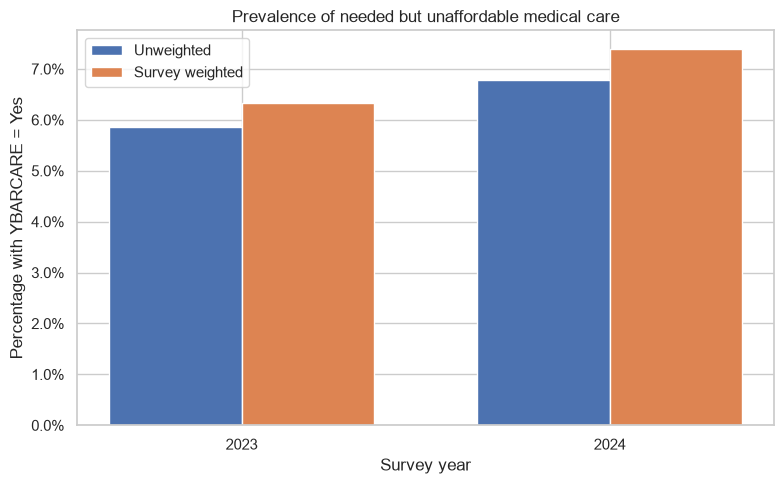

In [7]:
def weighted_binary_rate(data, outcome="target", weight="SAMPWEIGHT"):
    valid = data[[outcome, weight]].dropna()
    return np.average(valid[outcome], weights=valid[weight])

def prevalence_summary(data, group_name):
    return {
        "sample": group_name,
        "n": len(data),
        "positive_cases": int(data["target"].sum()),
        "unweighted_rate": data["target"].mean(),
        "weighted_rate": weighted_binary_rate(data),
    }

prevalence = pd.DataFrame(
    [prevalence_summary(group, str(year)) for year, group in train_df.groupby("YEAR")]
    + [prevalence_summary(train_df, "2023–2024 combined")]
)
prevalence_display = prevalence.copy()
prevalence_display["unweighted_rate"] = prevalence_display["unweighted_rate"].map(
    lambda value: f"{value:.2%}"
)
prevalence_display["weighted_rate"] = prevalence_display["weighted_rate"].map(
    lambda value: f"{value:.2%}"
)
display(prevalence_display)

plot_data = prevalence.loc[prevalence["sample"].isin(["2023", "2024"])].copy()
x = np.arange(len(plot_data))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, plot_data["unweighted_rate"], width, label="Unweighted")
ax.bar(x + width / 2, plot_data["weighted_rate"], width, label="Survey weighted")
ax.set_xticks(x, plot_data["sample"])
ax.set_xlabel("Survey year")
ax.set_ylabel("Percentage with YBARCARE = Yes")
ax.set_title("Prevalence of needed but unaffordable medical care")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()


In [8]:
LABELS = {
    "REGION": {1: "Northeast", 2: "Midwest", 3: "South", 4: "West"},
    "SEX": {1: "Male", 2: "Female"},
    "HISPRACE": {
        1: "Hispanic", 2: "Non-Hispanic White",
        3: "Non-Hispanic Black", 4: "Non-Hispanic Asian",
        5: "Non-Hispanic AI/AN", 6: "Non-Hispanic AI/AN + other",
        7: "Non-Hispanic other/multiple",
    },
    "EMPSTAT": {100: "Employed", 200: "Not employed"},
    "HEALTH": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "USUALPL": {1: "No", 2: "Yes", 3: "More than one place"},
    "HINOTCOVE": {1: "Has coverage", 2: "No coverage"},
}

def weighted_rate_by(data, group_column):
    grouped_data = data[[group_column, "target", "SAMPWEIGHT"]].dropna().copy()
    grouped_data["weighted_positive"] = grouped_data["target"] * grouped_data["SAMPWEIGHT"]
    result = (
        grouped_data.groupby(group_column, observed=True)
        .agg(
            n=("target", "size"),
            positive_cases=("target", "sum"),
            unweighted_rate=("target", "mean"),
            weighted_positive=("weighted_positive", "sum"),
            total_weight=("SAMPWEIGHT", "sum"),
        ).reset_index()
    )
    result["weighted_rate"] = result["weighted_positive"] / result["total_weight"]
    mapping = LABELS.get(group_column, {})
    result["group_label"] = result[group_column].map(mapping)
    result["group_label"] = result["group_label"].fillna(result[group_column].astype(str))
    return result

def plot_weighted_rate(ax, data, group_column, title):
    rates = weighted_rate_by(data, group_column)
    ax.bar(rates["group_label"], rates["weighted_rate"], color="#4C78A8")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Survey-weighted YBARCARE rate")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis="x", rotation=30)
    return rates


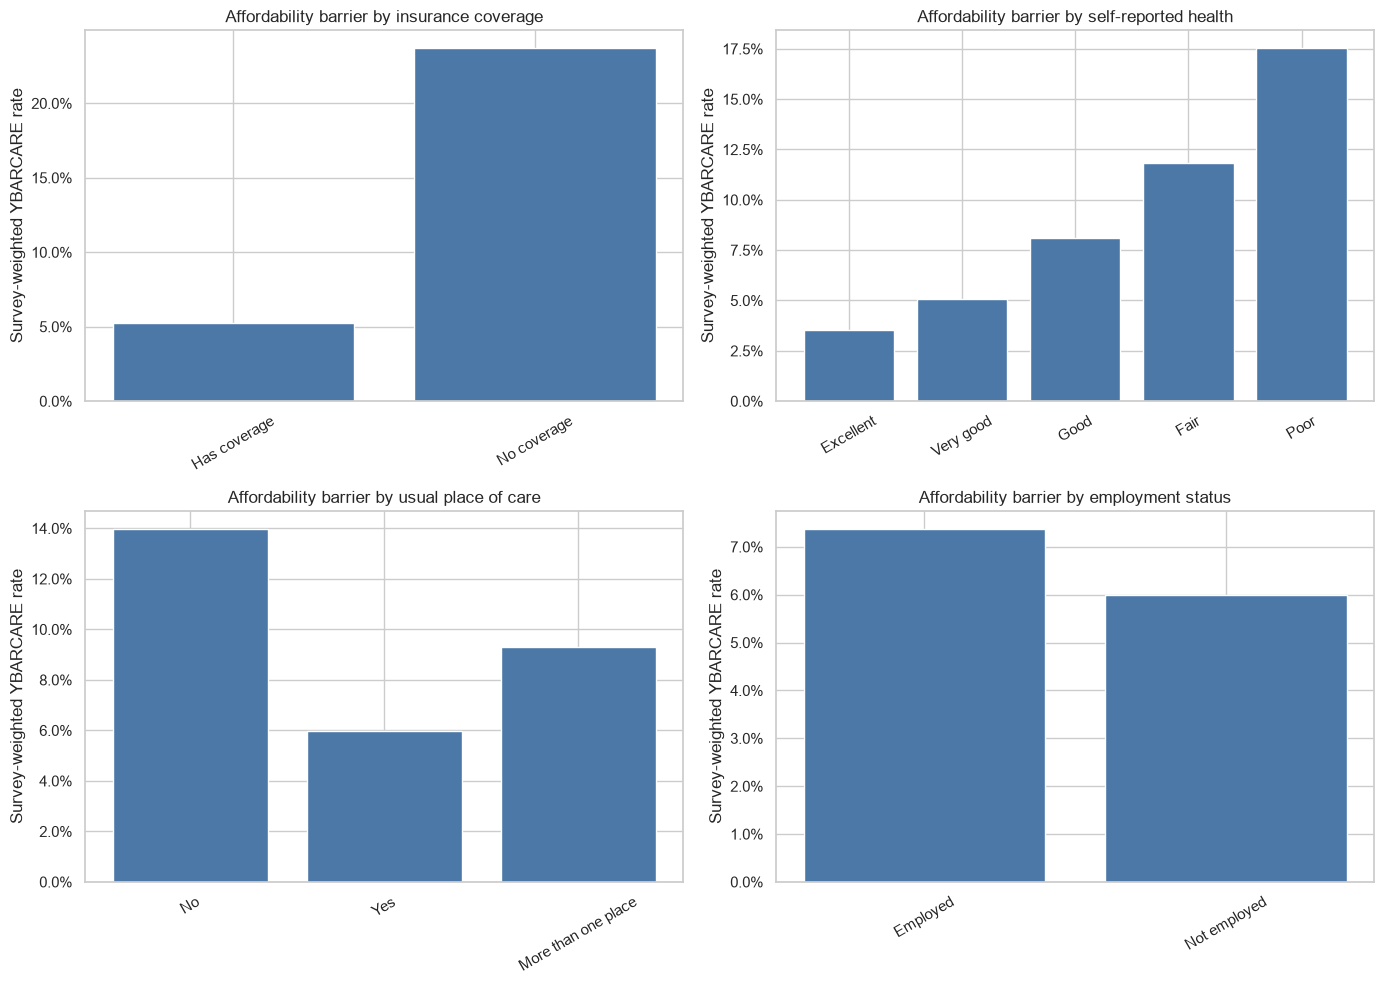

,group_label,n,unweighted_rate,weighted_rate
0,Has coverage,57166,0.050,0.052
1,No coverage,4303,0.238,0.237


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
insurance_rates = plot_weighted_rate(
    axes[0, 0], train_df, "HINOTCOVE", "Affordability barrier by insurance coverage"
)
plot_weighted_rate(
    axes[0, 1], train_df, "HEALTH", "Affordability barrier by self-reported health"
)
plot_weighted_rate(
    axes[1, 0], train_df, "USUALPL", "Affordability barrier by usual place of care"
)
plot_weighted_rate(
    axes[1, 1], train_df, "EMPSTAT", "Affordability barrier by employment status"
)
plt.tight_layout()
plt.show()
display(insurance_rates[["group_label", "n", "unweighted_rate", "weighted_rate"]])


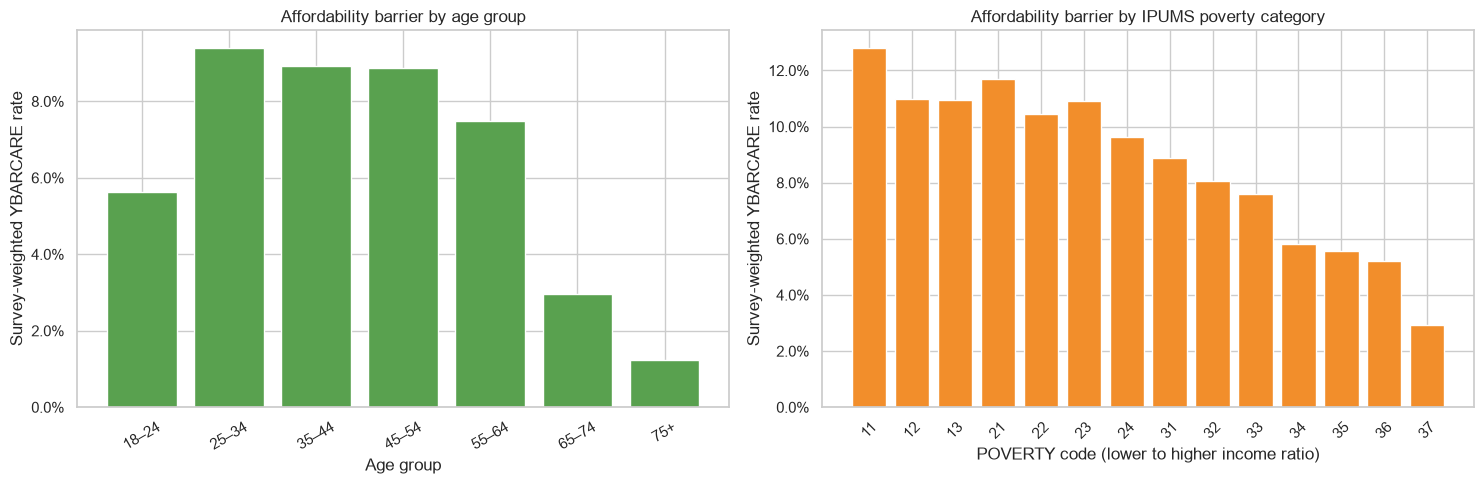

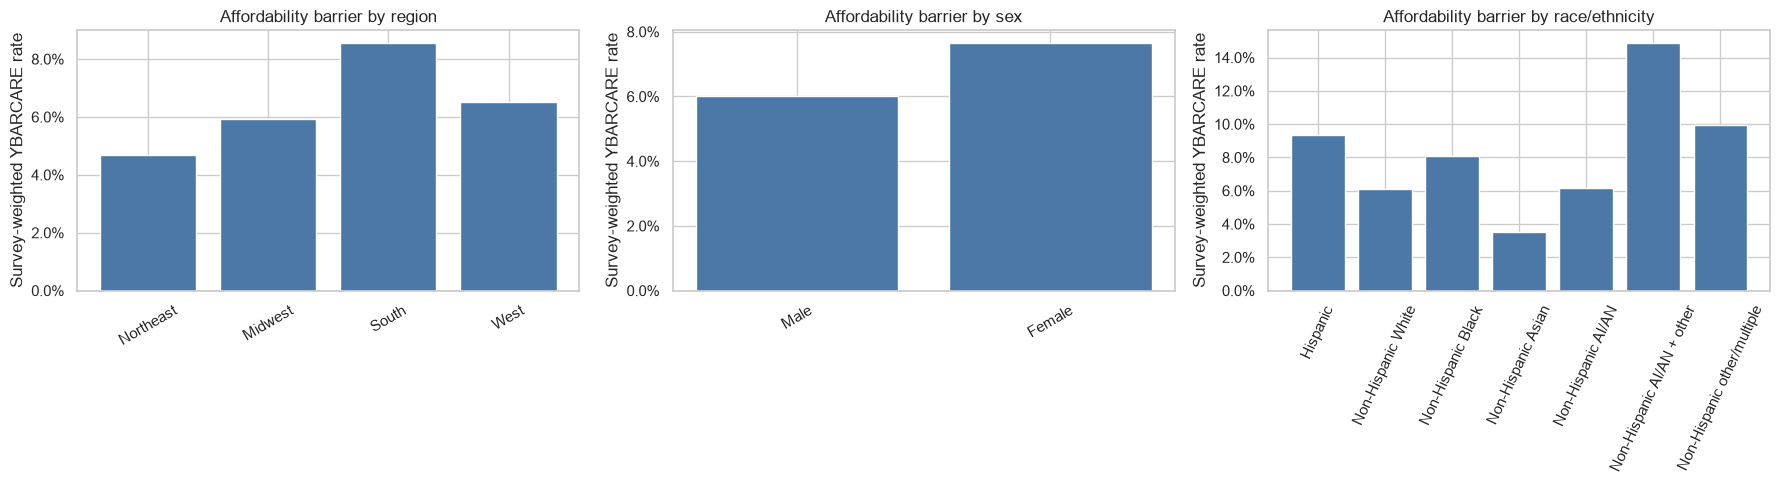

In [10]:
eda_age = train_df.copy()
eda_age["AGE_GROUP"] = pd.cut(
    eda_age["AGE"],
    bins=[17, 24, 34, 44, 54, 64, 74, np.inf],
    labels=["18–24", "25–34", "35–44", "45–54", "55–64", "65–74", "75+"],
)
age_rates = weighted_rate_by(eda_age, "AGE_GROUP")
poverty_rates = weighted_rate_by(train_df, "POVERTY").sort_values("POVERTY")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(age_rates["group_label"], age_rates["weighted_rate"], color="#59A14F")
axes[0].set_title("Affordability barrier by age group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Survey-weighted YBARCARE rate")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(poverty_rates["group_label"], poverty_rates["weighted_rate"], color="#F28E2B")
axes[1].set_title("Affordability barrier by IPUMS poverty category")
axes[1].set_xlabel("POVERTY code (lower to higher income ratio)")
axes[1].set_ylabel("Survey-weighted YBARCARE rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_weighted_rate(axes[0], train_df, "REGION", "Affordability barrier by region")
plot_weighted_rate(axes[1], train_df, "SEX", "Affordability barrier by sex")
plot_weighted_rate(axes[2], train_df, "HISPRACE", "Affordability barrier by race/ethnicity")
axes[2].tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()


### Exploratory data analysis findings

After cleaning, the 2023–2024 development dataset contains 61,630 sample adults with valid `YBARCARE` responses. Of these, 3,911 reported needing medical care but not receiving it because they could not afford it. The combined unweighted prevalence was 6.35%, while the survey-weighted prevalence was 6.86%. The weighted rate increased from 6.33% in 2023 to 7.39% in 2024. Because fewer than 7% of observations belong to the positive class, the outcome is imbalanced. Therefore, accuracy alone will not be an appropriate model-evaluation metric.

Insurance coverage showed a strong relationship with the outcome. The weighted affordability-barrier rate was 23.71% among adults without insurance, compared with 5.23% among adults with insurance coverage. This suggests that insurance status may be an important predictor.

A socioeconomic pattern was also visible. The weighted outcome rate generally decreased as the family-income-to-poverty ratio increased, falling from 12.79% in poverty category 11 to 2.92% in category 37. Employed adults had a weighted rate of 7.38%, compared with 5.99% among adults who were not employed. This employment result should be interpreted carefully because employment is related to age, retirement, insurance coverage, and other characteristics.

Health status displayed a clear gradient. The weighted outcome rate increased from 3.53% among adults reporting excellent health to 17.54% among those reporting poor health. Adults without a usual place of medical care also had a higher weighted rate of 13.98%, compared with 5.97% among adults with a usual place of care.

The outcome varied across demographic groups. It was most common among adults aged 25–34, with a weighted rate of 9.38%, and fell to 1.24% among adults aged 75 or older. The South had the highest regional rate at 8.56%, while the Northeast had the lowest at 4.67%. The weighted rate was 7.66% among females and 6.02% among males.

Differences were also observed across racial and ethnic categories. For example, the weighted rate was 9.37% among Hispanic adults, 8.10% among non-Hispanic Black adults, 6.09% among non-Hispanic White adults, and 3.54% among non-Hispanic Asian adults. Some race and ethnicity categories contain relatively small samples, so their estimates should be interpreted cautiously.

After special response codes were converted to missing values, `EMPSTAT` had the most missing observations at 3.22%. Missingness in all other predictors was below 0.5%. These missing predictor values will be handled through imputation inside the future preprocessing pipeline.

Overall, the EDA indicates that insurance coverage, poverty, health status, usual source of care, age, and other characteristics contain potentially useful predictive information. However, these are unadjusted one-variable relationships. Later classification models will examine the predictors together, and the findings should not be interpreted as causal effects.